# 07b · Validación e interpretación — abrir la prueba, una sola vez

> Continúa `01b_caso_negocio_aprueba_o_no.ipynb` (**aprueba con 70 o más; con menos de 70 pierde el curso**; clase de interés `Fail`, 69,2 %; costos 5 : 1),
> `04b_features_aprueba_o_no.ipynb` (28 variables), `05b_torneo_aprueba_o_no.ipynb` (**ganador: regresión logística**) y
> `06b_optimizacion_aprueba_o_no.ipynb` (**se quedan los parámetros de partida**: `C = 1`, umbral 1/6 ≈ 0,167).
> Dataset: `data/student_exam_performance.csv`. Plantilla: `notebooks/07_validacion_interpretacion.ipynb`. Ejemplo de referencia: `material-del-curso/ejemplo-creditsight/notebooks/07_validacion_interpretacion.ipynb`.

Hasta aquí **nadie ha mirado el conjunto de prueba** (el 20 % de los estudiantes: 20.000). Hoy se abre, **una sola vez**, para medir cómo se comportará el modelo con estudiantes nuevos. El orden importa:

1. Con estudiantes **reservados del entrenamiento** (no con la prueba) se decide si se calibran las probabilidades.
2. Las decisiones se **escriben y se guardan con fecha y hora** *antes* de abrir nada.
3. Recién entonces se abre la prueba, y su resultado **no se usa para volver a decidir**.

**Diferencias con el ejemplo CreditSight.** Allí había dos finalistas y 3 clases, y los intervalos remuestreaban **clientes** (cada uno tenía 8 meses). Aquí hay **un solo modelo**, la decisión es un **umbral** sobre P(`Fail`) (no un `argmin` de costos) y cada fila es un **estudiante distinto** (`student_id` único), por eso el intervalo remuestrea **filas**. En cambio sí se añade lo que el caso exige: **equidad por grupo** (`gender`, `family_income`, `urban_rural`, `school_type`…), que allí no se pedía.

**Regla para comparar con la estrategia sin modelo (escrita ANTES de mirar):** el modelo «sirve» solo si (a) todo el intervalo del 95 % de la diferencia de costo (modelo − «avisar a todos») queda por debajo de cero **y** (b) el intervalo del NPV queda por encima de 83,3 % (el mínimo de la etapa 1).

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

import json

import joblib
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from proyecto.data.cleaning import TARGET
from proyecto.data.split import make_folds, split_train_test
from proyecto.features.engineering import STAGE4_ADD_MISSING_INDICATOR, STAGE4_DROP, feature_columns
from proyecto.models.train import (FALSE_NEGATIVE_COST, FALSE_POSITIVE_COST, build_pipeline, business_metrics,
                                   decision_threshold, encode_target, metrics_from_proba)
from proyecto.models.tuning import bootstrap_cost_difference, make_lr
from proyecto.models.validation import (age_band, coefficient_table, decide_calibration, freeze_decisions, metric_with_ci,
                                        open_test_once, segment_table, shap_importance, student_contributions)

ROOT = Path.cwd().resolve().parent
REPORTS, MODELS, PROCESSED = ROOT / "reports", ROOT / "models", ROOT / "data" / "processed"
for carpeta in (REPORTS, MODELS):
    carpeta.mkdir(exist_ok=True)
SEED = 42
MARCA = REPORTS / "prueba_abierta.txt"                      # existe solo después de abrir la prueba
CACHE = PROCESSED / "prueba_probabilidades.joblib"          # lo que salió de la prueba (para no volver a mirarla)
OPCIONES = dict(drop=STAGE4_DROP, add_missing_indicator=STAGE4_ADD_MISSING_INDICATOR, scale=True)   # las 28 variables de la etapa 4

## 0. Cargar los datos de entrenamiento

Solo se carga el **entrenamiento** (`train.joblib`) y la tabla de auditoría del entrenamiento. `test.joblib` **no se toca hasta la sección 3**.

In [2]:
train_path = PROCESSED / "train.joblib"
assert train_path.exists(), "Falta data/processed/train.joblib: ejecuta antes el notebook 03b_preprocesamiento_aprueba_o_no."
train = joblib.load(train_path)
X_train, y_train = train.drop(columns=[TARGET]), encode_target(train[TARGET])

checks = {
    "80.000 estudiantes de entrenamiento": len(train) == 80_000,
    "cada estudiante aparece una sola vez (índice único)": train.index.is_unique,
    "el objetivo no está entre las entradas": TARGET not in X_train.columns,
    "Fail ≈ 69,2 %": abs(y_train.mean() - 0.692) < 0.005,
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
display(result)
print(f"entrenamiento: {len(train):,} estudiantes · Fail = {y_train.mean():.1%} · la prueba sigue cerrada" + (" (¡ya se abrió antes: ver reports/prueba_abierta.txt!)" if MARCA.exists() else ""))

80.000 estudiantes de entrenamiento                    True
cada estudiante aparece una sola vez (índice único)    True
el objetivo no está entre las entradas                 True
Fail ≈ 69,2 %                                          True
Name: se cumple, dtype: bool

entrenamiento: 80,000 estudiantes · Fail = 69.2% · la prueba sigue cerrada


## 1. Decisiones congeladas — **antes** de abrir la prueba

**Qué ya está decidido** (con validación, etapas 4 a 6; el detalle está en `reports/04_features.md`, `05_torneo.md` y `06_optimizacion.md`):

- **Modelo:** regresión logística con las 28 variables de la etapa 4.
- **Parámetros:** los de `reports/06_best_params.json` (la optimización no mejoró nada distinguible del ruido, así que son los de **partida**).
- **Regla de decisión:** avisar si P(`Fail`) ≥ el umbral de ese archivo (1/6 ≈ 0,167 = 1 / (1 + 5)).
- **Métrica principal:** costo esperado por estudiante (5 : 1); de control, *recall* de `Fail` y NPV.

**Lo que falta decidir aquí: ¿calibrar las probabilidades?** El umbral 1/6 solo es el óptimo si las probabilidades están bien calibradas. Se decide con los **20.000 estudiantes reservados de la etapa 6** (los mismos, semilla 7), nunca con la prueba. Se compara el modelo tal cual contra el mismo modelo calibrado (método sigmoide, ajustado con validación cruzada dentro del 75 % de búsqueda).

**Regla escrita de antemano:** se calibra **solo si** el *log loss* mejora en más de 0,005 **y** el costo no empeora de forma distinguible (el límite inferior del intervalo del 95 % de «calibrado − sin calibrar» no es positivo).

In [3]:
mejores = json.loads((REPORTS / "06_best_params.json").read_text(encoding="utf-8"))
PARAMS = {"C": float(mejores["parametros"]["C"])}
UMBRAL = float(mejores["parametros"]["threshold"])
assert mejores["modelo"] == "regresión logística"
assert abs(UMBRAL - decision_threshold()) < 1e-9, "el umbral debería ser el teórico 1/6 (decisión de la etapa 6)"
print("Parámetros congelados por la etapa 6:", PARAMS, "· umbral:", round(UMBRAL, 4), "·", mejores["decision"])

# la misma reserva de la etapa 6 (25 % del entrenamiento, semilla 7, por fila y estratificada)
busqueda, reservado = split_train_test(train, target=TARGET, test_size=0.25, seed=7)
X_busq, y_busq = busqueda.drop(columns=[TARGET]), encode_target(busqueda[TARGET])
X_res, y_res = reservado.drop(columns=[TARGET]), encode_target(reservado[TARGET])
assert set(busqueda.index).isdisjoint(reservado.index) and len(busqueda) + len(reservado) == len(train)

sin_calibrar = build_pipeline(make_lr(PARAMS), **OPCIONES).fit(X_busq, y_busq)
pliegues = make_folds(busqueda[TARGET], n_splits=3, seed=SEED)
calibrado = CalibratedClassifierCV(build_pipeline(make_lr(PARAMS), **OPCIONES), method="sigmoid", cv=pliegues).fit(X_busq, y_busq)
p_sin, p_cal = sin_calibrar.predict_proba(X_res)[:, 1], calibrado.predict_proba(X_res)[:, 1]

m_sin, m_cal = metrics_from_proba(y_res, p_sin, UMBRAL), metrics_from_proba(y_res, p_cal, UMBRAL)
d_cal, b_cal, a_cal = bootstrap_cost_difference(y_res, p_cal, p_sin, UMBRAL, UMBRAL, n_boot=1000, seed=SEED)
CALIBRAR = decide_calibration(m_sin["log_loss"], m_cal["log_loss"], b_cal)

tabla_cal = pd.DataFrame({"sin calibrar": m_sin, "calibrado": m_cal}).loc[["log_loss", "roc_auc", "cost", "recall_fail", "npv", "alerts_per_100"]]
display(tabla_cal.round(4))
print(f"Diferencia de costo (calibrado − sin calibrar) en {len(reservado):,} estudiantes reservados: {d_cal:+.5f}   IC 95 %: [{b_cal:+.5f}, {a_cal:+.5f}]")
print(f"log loss: {m_sin['log_loss']:.4f} → {m_cal['log_loss']:.4f} (hay que ganar más de 0,005)   ¿calibrar? {'SÍ' if CALIBRAR else 'NO'}")

Parámetros congelados por la etapa 6: {'C': 1.0} · umbral: 0.1667 · parámetros de partida (la mejora no se distingue del ruido)


,sin calibrar,calibrado
log_loss,0.3737,0.3737
roc_auc,0.8917,0.8917
cost,0.2547,0.2547
recall_fail,0.9888,0.9889
npv,0.9222,0.9228
alerts_per_100,90.0350,90.0950


Diferencia de costo (calibrado − sin calibrar) en 20,000 estudiantes reservados: +0.00000   IC 95 %: [-0.00085, +0.00060]
log loss: 0.3737 → 0.3737 (hay que ganar más de 0,005)   ¿calibrar? NO


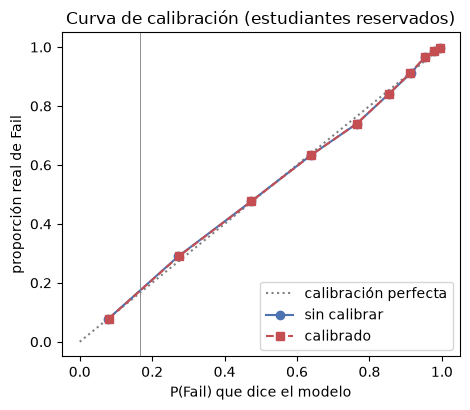

In [4]:
frac_sin, medio_sin = calibration_curve(y_res, p_sin, n_bins=10, strategy="quantile")
frac_cal, medio_cal = calibration_curve(y_res, p_cal, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 1], [0, 1], ":", color="grey", label="calibración perfecta")
ax.plot(medio_sin, frac_sin, "o-", color="#4c72b0", label="sin calibrar")
ax.plot(medio_cal, frac_cal, "s--", color="#c44e52", label="calibrado")
ax.axvline(UMBRAL, color="grey", linewidth=0.6)
ax.set_xlabel("P(Fail) que dice el modelo"); ax.set_ylabel("proporción real de Fail"); ax.set_title("Curva de calibración (estudiantes reservados)")
ax.legend(); plt.tight_layout(); plt.show()

### Las decisiones, por escrito

Se guardan en `reports/07_decisiones_congeladas.json` **con fecha y hora**, antes de abrir la prueba. Si más adelante alguien pregunta «¿decidieron esto antes o después de ver la prueba?», la respuesta está en ese archivo. Si la prueba ya se abrió, el archivo **no se reescribe**.

In [5]:
decisiones = freeze_decisions({
    "modelo_final": "regresión logística",
    "variables": "28 de la etapa 4 (feature_columns(drop=STAGE4_DROP), sin indicador de vacío)",
    "parametros": PARAMS,
    "umbral": UMBRAL,
    "calibrar": CALIBRAR,
    "metrica_principal": "costo esperado por estudiante (falso negativo : falso positivo = 5 : 1, supuesto); menor es mejor",
    "metricas_de_control": ["recall de Fail", "NPV (mínimo 83,3 %)", "alertas por 100"],
    "regla_de_decision": "avisar si P(Fail) >= umbral (1/6 = 1 / (1 + 5))",
    "comparacion": "contra «avisar a todos» (el DummyRegressor es idéntico)",
    "como_se_decidio": "etapas 4 a 6 con validación cruzada; calibración con los 20.000 estudiantes reservados de la etapa 6; la prueba no se miró",
    "calibracion": {"log_loss_sin": m_sin["log_loss"], "log_loss_con": m_cal["log_loss"], "costo_sin": m_sin["cost"], "costo_con": m_cal["cost"],
                    "diferencia_costo": d_cal, "intervalo_95": [b_cal, a_cal]},
}, REPORTS / "07_decisiones_congeladas.json", test_opened=MARCA.exists())
print("Decisiones congeladas el", decisiones["fecha_y_hora"], "· modelo:", decisiones["modelo_final"], "· parámetros:", decisiones["parametros"], "· calibrar:", decisiones["calibrar"])
CALIBRAR, PARAMS, UMBRAL = decisiones["calibrar"], decisiones["parametros"], decisiones["umbral"]     # si la prueba ya se abrió, valen las congeladas

Decisiones congeladas el 2026-11-05T20:12:56 · modelo: regresión logística · parámetros: {'C': 1.0} · calibrar: False


## 2. Entrenar el modelo final con **todo** el entrenamiento

Con las decisiones tomadas, el modelo se ajusta con los 80.000 estudiantes de entrenamiento (la reserva incluida) y se guarda **entero** (preprocesamiento + modelo [+ calibración]) en `models/final_pipeline.joblib`, listo para registrar en el notebook 08. También se conserva la versión **sin calibrar** para explicarla en la sección 6 (la calibración solo reajusta las probabilidades).

In [6]:
base_final = build_pipeline(make_lr(PARAMS), **OPCIONES).fit(X_train, y_train)       # sin calibrar (también sirve para explicar)
if CALIBRAR:
    pliegues_train = make_folds(train[TARGET], n_splits=3, seed=SEED)
    modelo_final = CalibratedClassifierCV(build_pipeline(make_lr(PARAMS), **OPCIONES), method="sigmoid", cv=pliegues_train).fit(X_train, y_train)
else:
    modelo_final = base_final
joblib.dump(modelo_final, MODELS / "final_pipeline.joblib")
numericas, categoricas = feature_columns(drop=STAGE4_DROP)
print("modelo final ajustado y guardado:", type(modelo_final).__name__, "· variables:", len(numericas) + len(categoricas))

modelo final ajustado y guardado: Pipeline · variables: 28


## 3. Abrir la prueba — **una sola vez**

Esta celda **escribe una marca** (`reports/prueba_abierta.txt`) y guarda lo que salió de la prueba (`data/processed/prueba_probabilidades.joblib`). Si el notebook se vuelve a ejecutar, **no vuelve a cargar ni a evaluar la prueba**: reutiliza lo guardado y lo dice. Así se puede re-ejecutar el resto sin «mirar otra vez».

A partir de aquí **no se cambia nada del modelo ni del umbral**.

In [7]:
def evaluar_prueba():
    test = joblib.load(PROCESSED / "test.joblib")          # único lugar donde se carga la prueba
    assert test.index.is_unique and not set(test.index) & set(train.index), "la prueba no debe compartir estudiantes con el entrenamiento"
    return {"index": test.index.to_numpy(), "y_fail": encode_target(test[TARGET]),
            "p_fail": modelo_final.predict_proba(test.drop(columns=[TARGET]))[:, 1]}

salida, abierta_ahora = open_test_once(MARCA, CACHE, evaluar_prueba, note=f"Modelo {decisiones['modelo_final']}, calibrar={CALIBRAR}, umbral {UMBRAL:.4f}.")
if abierta_ahora:
    print("Prueba abierta AHORA; marca escrita en", MARCA.name)
else:
    print("La prueba ya se abrió:", MARCA.read_text(encoding="utf-8").strip())
    print("Se reutilizan los resultados guardados; no se vuelve a evaluar el modelo con la prueba.")
idx_test, y_test, p_test = salida["index"], salida["y_fail"], salida["p_fail"]
p_base = np.ones(len(y_test))                 # «avisar a todos»: P(Fail) = 1 para todos (siempre >= umbral)
print(f"prueba: {len(y_test):,} estudiantes · Fail = {y_test.mean():.1%}")

Prueba abierta AHORA; marca escrita en prueba_abierta.txt
prueba: 20,000 estudiantes · Fail = 69.2%


In [8]:
m_test = metrics_from_proba(y_test, p_test, UMBRAL)
m_base = business_metrics(y_test, np.ones(len(y_test), dtype=bool))
tablero = pd.DataFrame({"modelo final": m_test, "avisar a todos": m_base}).loc[
    ["cost", "recall_fail", "precision_fail", "npv", "specificity", "alerts_per_100", "accuracy", "balanced_accuracy", "roc_auc", "pr_auc_fail", "log_loss"]]
display(tablero.round(4))

,modelo final,avisar a todos
cost,0.2550,0.3079
recall_fail,0.9879,1.0000
precision_fail,0.7625,0.6921
npv,0.9187,NaN
specificity,0.3082,0.0000
alerts_per_100,89.6700,100.0000
accuracy,0.7786,0.6921
balanced_accuracy,0.6480,0.5000
roc_auc,0.8956,NaN
pr_auc_fail,0.9496,NaN


## 4. Intervalo y comparación con la estrategia sin modelo — remuestreando **estudiantes**

Una cifra sin intervalo no dice cuánto confiar en ella. Como cada fila es un estudiante distinto, el intervalo del 95 % remuestrea **filas** (1.000 remuestreos). Se miran las tres métricas de la etapa 1 (costo, *recall* de `Fail`, NPV) y se **compara con «avisar a todos»**: la pregunta es si el modelo lo supera **con confianza**.

In [9]:
filas = []
for etiqueta, clave in (("costo por estudiante (menor es mejor)", "cost"), ("recall de Fail", "recall_fail"), ("NPV (mínimo exigido: 0,833)", "npv"),
                        ("alertas por 100", "alerts_per_100")):
    valor, bajo, alto = metric_with_ci(y_test, p_test, UMBRAL, clave, seed=SEED)
    filas.append([etiqueta, valor, bajo, alto])
v_b, b_b, a_b = metric_with_ci(y_test, p_base, UMBRAL, "cost", seed=SEED)
filas.append(["costo de «avisar a todos»", v_b, b_b, a_b])
dif, d_bajo, d_alto = bootstrap_cost_difference(y_test, p_test, p_base, UMBRAL, UMBRAL, n_boot=1000, seed=SEED)
filas.append(["costo: modelo − «avisar a todos»", dif, d_bajo, d_alto])
intervalos = pd.DataFrame(filas, columns=["medida", "valor", "IC 95 % inferior", "IC 95 % superior"]).set_index("medida")
display(intervalos.round(4))

npv_bajo = intervalos.loc["NPV (mínimo exigido: 0,833)", "IC 95 % inferior"]
supera_costo, supera_npv = bool(d_alto < 0), bool(npv_bajo > 5 / 6)
supera = supera_costo and supera_npv
print(f"(a) ¿todo el intervalo de la diferencia de costo está por debajo de cero? {'SÍ' if supera_costo else 'NO'}   ({dif:+.4f}, IC [{d_bajo:+.4f}, {d_alto:+.4f}])")
print(f"(b) ¿todo el intervalo del NPV está por encima de 0,833? {'SÍ' if supera_npv else 'NO'}   (límite inferior {npv_bajo:.4f})")
print("¿El modelo supera a «avisar a todos» con confianza (a y b)?", "SÍ" if supera else "NO")
print(f"Ahorro por estudiante: {-dif:.4f} ({-dif / v_b:.1%} del costo de avisar a todos)")

,valor,IC 95 % inferior,IC 95 % superior
medida,,,
costo por estudiante (menor es mejor),0.2550,0.2467,0.2634
recall de Fail,0.9879,0.9861,0.9896
"NPV (mínimo exigido: 0,833)",0.9187,0.9072,0.9302
alertas por 100,89.6700,89.2799,90.0650
costo de «avisar a todos»,0.3079,0.3016,0.3142
costo: modelo − «avisar a todos»,-0.0529,-0.0604,-0.0455


(a) ¿todo el intervalo de la diferencia de costo está por debajo de cero? SÍ   (-0.0529, IC [-0.0604, -0.0455])
(b) ¿todo el intervalo del NPV está por encima de 0,833? SÍ   (límite inferior 0.9072)
¿El modelo supera a «avisar a todos» con confianza (a y b)? SÍ
Ahorro por estudiante: 0.0529 (17.2% del costo de avisar a todos)


**Cómo leerlo.** El costo sale del supuesto 5 : 1, que la institución debe validar: con otros costos el umbral y el ahorro cambian. Y recuerda de la etapa 6: con ese umbral el modelo avisa a ≈ 90 de cada 100 y deja tranquilo a pocos; el **ahorro** viene de no tranquilizar por error a quien pierde el curso, no de «adivinar» quién aprueba.

## 5. Equidad por grupo y carga de trabajo — lo que el promedio no ve

Un buen promedio puede esconder un grupo al que el modelo le va peor. Se audita con las columnas **sensibles** que **no entran** al modelo (`gender`, `family_income`) o que entran y conviene vigilar (`urban_rural`, `school_type`), más `education_level` y la edad por tramos (el dataset incluye **menores de edad**). Salen de `audit_test.joblib`, alineadas por `student_id`. Para cada grupo: casos, % real de `Fail`, % de alertas, *recall*, precisión, NPV y costo.

> Ojo: que el *recall* y el % de alertas sean parecidos entre grupos no prueba que el modelo sea «justo»; solo que no hay una brecha **visible en estas medidas**. Y un grupo con pocos casos tiene números inestables.

In [10]:
audit_test = joblib.load(PROCESSED / "audit_test.joblib").loc[idx_test]               # mismo orden que la prueba
assert (audit_test.index.to_numpy() == idx_test).all()
audit_test["age_band"] = age_band(audit_test["age"])
COLUMNAS_GRUPO = ["gender", "family_income", "urban_rural", "school_type", "education_level", "age_band"]
segmentos = segment_table(y_test, p_test, UMBRAL, audit_test, COLUMNAS_GRUPO)
display(segmentos.round(3))

casos  % Fail real  % alertas  recall Fail  precisión Fail    NPV  costo
variable        grupo                                                                                  
gender          Female          9804       69.441     89.616        0.988           0.766  0.921  0.251
                Male            9812       68.946     89.615        0.987           0.759  0.914  0.260
                Other            384       70.052     92.448        1.000           0.758  1.000  0.224
family_income   High            2044       59.687     83.953        0.984           0.700  0.942  0.298
                Low             3846       76.391     93.240        0.990           0.811  0.888  0.214
                Lower-Middle    5104       70.905     90.948        0.992           0.773  0.937  0.235
                Middle          6026       69.018     89.562        0.987           0.761  0.917  0.257
                Upper-Middle    2980       63.960     87.013        0.980           0.720  0.899  0.309
urban_rural     Rural           4034       69.757     90.803        0.988           0.759  0.911  0.260
                Suburban        7059       68.848     89.404        0.987           0.760  0.918  0.257
                Urban           8907       69.249     89.368        0.988           0.766  0.922  0.251
school_type     Charter         2037       71.870     90.083        0.991           0.791  0.936  0.220
                Private         6983       68.524     89.732        0.989           0.755  0.923  0.259
                Public         10980       69.153     89.554        0.987           0.762  0.913  0.259
education_level High School    12009       69.231     89.658        0.989           0.764  0.925  0.251
                Undergraduate   7991       69.178     89.688        0.986           0.761  0.909  0.261
age_band        16–17           5638       69.244     89.429        0.986           0.763  0.908  0.260
                ≤15             5654       69.261     89.671        0.987           0.763  0.916  0.256
                ≥18             8708       69.155     89.825        0.989           0.762  0.928  0.251

In [11]:
brechas = segmentos.groupby(level="variable").agg(
    grupos=("casos", "size"), casos_min=("casos", "min"),
    brecha_recall=("recall Fail", lambda s: s.max() - s.min()), brecha_alertas=("% alertas", lambda s: s.max() - s.min()),
    brecha_NPV=("NPV", lambda s: s.max() - s.min()), brecha_Fail_real=("% Fail real", lambda s: s.max() - s.min()))
display(brechas.round(3))
peor = segmentos["recall Fail"].idxmin()
print(f"Grupo con menor recall de Fail: {peor} ({segmentos.loc[peor, 'recall Fail']:.3f}, {int(segmentos.loc[peor, 'casos']):,} casos).")

# Carga de trabajo: lo que decide el modelo frente a lo real
print(f"\nEl modelo avisa a {m_test['alerts_per_100']:.1f} de cada 100 estudiantes; en realidad pierden el curso {100 * y_test.mean():.1f} de cada 100.")
print(f"Si la institución solo pudiera tutorar al 30 % más riesgoso: precisión {m_test['precision_top30']:.3f}, recall {m_test['recall_top30']:.3f}, costo {m_test['cost_top30']:.3f} "
      f"(frente a {m_base['cost']:.3f} de avisar a todos): con capacidad limitada el costo 5 : 1 deja de ser la métrica adecuada.")

,grupos,casos_min,brecha_recall,brecha_alertas,brecha_NPV,brecha_Fail_real
variable,,,,,,
age_band,3,5638,0.003,0.397,0.020,0.106
education_level,2,7991,0.002,0.031,0.016,0.054
family_income,5,2044,0.012,9.287,0.054,16.704
gender,3,384,0.013,2.833,0.086,1.106
school_type,3,2037,0.004,0.530,0.023,3.347
urban_rural,3,4034,0.001,1.435,0.011,0.909


Grupo con menor recall de Fail: ('family_income', 'Upper-Middle') (0.980, 2,980 casos).

El modelo avisa a 89.7 de cada 100 estudiantes; en realidad pierden el curso 69.2 de cada 100.
Si la institución solo pudiera tutorar al 30 % más riesgoso: precisión 0.983, recall 0.426, costo 1.992 (frente a 0.308 de avisar a todos): con capacidad limitada el costo 5 : 1 deja de ser la métrica adecuada.


## 6. ¿Por qué decide así el modelo?

Como el modelo es una **regresión logística**, se puede mirar directamente: cada variable tiene un **coeficiente** (las numéricas están estandarizadas, así que son comparables; un coeficiente positivo empuja hacia `Fail`) y un *odds ratio* (`exp(coeficiente)`: cuánto se multiplican las probabilidades relativas de `Fail` por cada desviación estándar). Se complementa con **SHAP** (calculado sobre una muestra del **entrenamiento** y sobre el modelo **sin calibrar**).

> **El límite que hay que escribir siempre:** estas explicaciones describen **al modelo**, no **al mundo**. Que una variable pese mucho dice que el modelo se apoya en ella, no que *cause* que alguien pierda el curso. Y como las variables están correlacionadas, el reparto del crédito entre ellas es una convención, no una verdad.

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


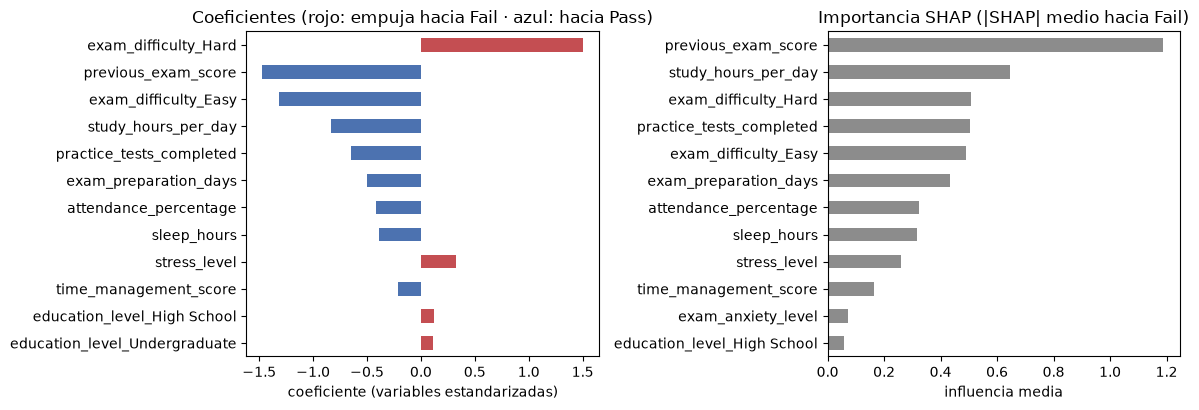

,coeficiente,odds ratio,|SHAP| medio
exam_difficulty_Hard,1.502,4.491,0.506
previous_exam_score,-1.469,0.230,1.188
exam_difficulty_Easy,-1.318,0.268,0.491
study_hours_per_day,-0.833,0.435,0.644
practice_tests_completed,-0.644,0.525,0.504
exam_preparation_days,-0.498,0.608,0.432
attendance_percentage,-0.419,0.657,0.325
sleep_hours,-0.391,0.677,0.317
stress_level,0.330,1.391,0.260
time_management_score,-0.209,0.811,0.164


In [12]:
coefs = coefficient_table(base_final)
muestra = X_train.sample(2000, random_state=0)                                          # solo entrenamiento
shap_imp = shap_importance(base_final, muestra)
top = coefs.head(12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
top["coeficiente"][::-1].plot.barh(ax=axes[0], color=["#c44e52" if v > 0 else "#4c72b0" for v in top["coeficiente"][::-1]])
axes[0].set_title("Coeficientes (rojo: empuja hacia Fail · azul: hacia Pass)"); axes[0].set_xlabel("coeficiente (variables estandarizadas)")
shap_imp.head(12)["|SHAP| medio"][::-1].plot.barh(ax=axes[1], color="#8c8c8c")
axes[1].set_title("Importancia SHAP (|SHAP| medio hacia Fail)"); axes[1].set_xlabel("influencia media")
plt.tight_layout(); plt.show()
display(pd.concat([coefs.head(12).round(3), shap_imp.round(3).reindex(coefs.head(12).index)], axis=1))

In [13]:
# Dos estudiantes concretos del ENTRENAMIENTO (no de la prueba): el de mayor y el de menor P(Fail) de la muestra
p_muestra = base_final.predict_proba(muestra)[:, 1]
for etiqueta, pos in (("mayor riesgo", int(np.argmax(p_muestra))), ("menor riesgo", int(np.argmin(p_muestra)))):
    print(f"--- Estudiante de {etiqueta} (P(Fail) = {p_muestra[pos]:.3f}) ---")
    display(student_contributions(base_final, muestra.iloc[[pos]]).round(3))

--- Estudiante de mayor riesgo (P(Fail) = 1.000) ---


,valor transformado,contribución al logit
previous_exam_score,-2.849,4.186
exam_difficulty_Hard,1.000,1.502
study_hours_per_day,-0.573,0.477
practice_tests_completed,-0.601,0.387
sleep_hours,-0.979,0.382
exam_preparation_days,-0.521,0.260


--- Estudiante de menor riesgo (P(Fail) = 0.001) ---


,valor transformado,contribución al logit
previous_exam_score,2.206,-3.242
study_hours_per_day,2.768,-2.306
practice_tests_completed,2.999,-1.933
attendance_percentage,2.043,-0.857
stress_level,-1.276,-0.421
exam_anxiety_level,-1.714,-0.151


In [14]:
# Variables de uso sensible o regulado entre las que SÍ usa el modelo
SENSIBLES = ["age", "gender", "family_income", "parent_education", "urban_rural", "school_type"]
usadas = set(numericas) | set(categoricas)
print("Sensibles que el modelo USA:", [c for c in SENSIBLES if c in usadas])
print("Sensibles que el modelo NO usa (solo se auditan):", [c for c in SENSIBLES if c not in usadas])
peso = shap_imp[[any(n == s or n.startswith(s + "_") for s in SENSIBLES if s in usadas) for n in shap_imp.index]]
print("\nPeso de las que usa (|SHAP| medio):")
print(peso.round(4).to_string())
print(f"Proporción de la influencia total que reparten entre todas: {peso['|SHAP| medio'].sum() / shap_imp['|SHAP| medio'].sum():.1%}")

Sensibles que el modelo USA: ['parent_education', 'urban_rural', 'school_type']
Sensibles que el modelo NO usa (solo se auditan): ['age', 'gender', 'family_income']

Peso de las que usa (|SHAP| medio):
                              |SHAP| medio
school_type_Public                  0.0504
urban_rural_Urban                   0.0380
school_type_Private                 0.0352
urban_rural_Suburban                0.0343
urban_rural_Rural                   0.0309
parent_education_High School        0.0224
parent_education_Associate          0.0149
parent_education_Bachelor           0.0145
school_type_Charter                 0.0113
parent_education_Doctorate          0.0084
parent_education_Master             0.0058
parent_education_Desconocido        0.0014
Proporción de la influencia total que reparten entre todas: 4.2%


## 7. Guardar los resultados de la etapa

Salen de aquí: `reports/07_metricas_test.json` (el que lee el notebook 08, con las decisiones y las métricas con su intervalo), `07_errores_por_segmento.csv`, `07_coeficientes.csv` y `07_importancia_shap.csv`. El informe escrito `reports/07_validacion.md` se redacta **con estas cifras**, no de memoria.

In [15]:
numerico = lambda d: {k: float(v) for k, v in d.items() if isinstance(v, (int, float, np.integer, np.floating))}
resultados = {
    "decisiones": decisiones,
    "prueba": {**numerico(m_test), "estudiantes": int(len(y_test)), "fail_real": float(y_test.mean())},
    "baseline_avisar_a_todos": numerico(m_base),
    "intervalos_95": intervalos.reset_index().to_dict(orient="records"),
    "supera_al_baseline_con_confianza": {"costo": supera_costo, "npv": supera_npv, "ambas": supera},
    "prueba_abierta": MARCA.read_text(encoding="utf-8").strip(),
}
(REPORTS / "07_metricas_test.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
segmentos.round(4).to_csv(REPORTS / "07_errores_por_segmento.csv", encoding="utf-8")
coefs.round(5).to_csv(REPORTS / "07_coeficientes.csv", encoding="utf-8")
shap_imp.round(5).to_csv(REPORTS / "07_importancia_shap.csv", encoding="utf-8")
print("guardado en reports/: 07_metricas_test.json, 07_errores_por_segmento.csv, 07_coeficientes.csv, 07_importancia_shap.csv, 07_decisiones_congeladas.json")

guardado en reports/: 07_metricas_test.json, 07_errores_por_segmento.csv, 07_coeficientes.csv, 07_importancia_shap.csv, 07_decisiones_congeladas.json


## 8. Las pruebas automáticas

Desde la raíz del repo: `pytest -q`. Las funciones de esta etapa (`src/proyecto/models/validation.py`) tienen pruebas con casos de mano en `tests/test_validation.py`: la regla de calibración, que las decisiones no se reescriban después de abrir la prueba, que **la prueba se evalúe una sola vez** (y falle en voz alta si se intenta reabrir), los intervalos, la tabla por grupo (sin perder ni duplicar estudiantes; NaN y no 0 cuando una razón no existe) y la interpretación (los coeficientes y SHAP ponen primero la señal real; las contribuciones suman el *logit* del modelo).

In [16]:
import subprocess

run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_validation.py", "tests/test_tuning.py", "tests/test_train.py",
                      "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print((run.stdout or run.stderr).strip()[-400:])

lflow/store/tracking/sqlalchemy_store.py:327: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1)
    sqlalchemy.orm.configure_mappers()

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
49 passed, 1 warning in 8.87s


## Entregable de esta etapa

- [ ] Las **decisiones** (modelo, parámetros, calibración, umbral, métrica) están en `reports/07_decisiones_congeladas.json` con fecha y hora **anteriores** a `reports/prueba_abierta.txt`.
- [ ] La calibración se decidió con los estudiantes reservados, **no** con la prueba.
- [ ] La prueba se abrió **una sola vez** (hay marca) y no se cambió nada después de verla.
- [ ] Hay **intervalo del 95 %** para costo, *recall* y NPV, y la **comparación con «avisar a todos»**.
- [ ] Hay **equidad por grupo** (incluida la edad por tramos) y se señala el grupo con peor desempeño.
- [ ] La **interpretación** (coeficientes y SHAP) incluye su límite: explica al modelo, no al mundo.
- [ ] `reports/07_validacion.md` y `reports/07_metricas_test.json` completados; `models/final_pipeline.joblib` guardado.
- [ ] El grupo aprobó las decisiones y la institución confirmó los supuestos (costos 5 : 1; `exam_difficulty` se conoce antes de avisar; capacidad de tutoría).

**Siguiente:** `08_registro_modelo.ipynb`: registrar el modelo final con sus métricas en MLflow (Databricks o local).